<a href="https://colab.research.google.com/github/A1omo/mi-dashboard-ventas/blob/main/Taller_Graficos_Dashboard_Ventas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts** para Gemini, en el mismo Colab.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (1).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [2]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

,total
producto,
Cuaderno,20712345
Block de notas,14292347
Resma carta,13133570
Marcador,10020786
Colores x12,9419625


<Axes: title={'center': 'Top 5 productos por ingresos'}, ylabel='producto'>

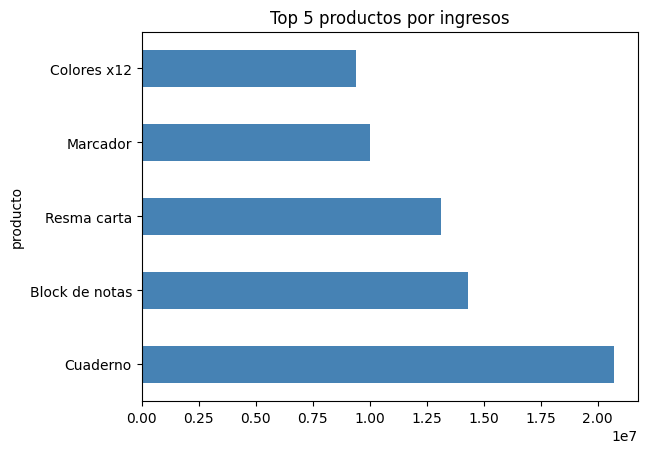

In [3]:
# Ejercicio 1


#df.groupby('columna')['otra_columna'].función() agrupa las filas que comparten el mismo valor en 'columna', y aplica una función (sum, mean, count, size...) sobre 'otra_columna'
top_productos = df.groupby('producto')['total'].sum().sort_values(ascending=False).head(5)
display(top_productos)

top_productos.plot.barh(color="steelblue", title="Top 5 productos por ingresos")



### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

ciudad,Bogotá,Medellín
mes,,
1,4815405,3504905
2,3037200,2262080
3,3629385,1342665
4,3117990,1107910
5,3937775,3164730
6,1631810,2848235
7,2781218,2771377
8,3706217,4092446
9,2245001,969551


<Axes: title={'center': 'Ventas Bogotá y Medellín'}, xlabel='mes'>

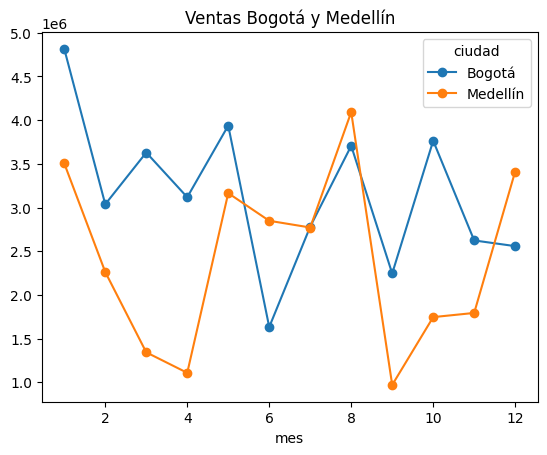

In [4]:
# Ejercicio 2
comparacion_dos_ciudades = df[df['ciudad'].isin(['Bogotá', 'Medellín'])]
ing_mes_ciudad = comparacion_dos_ciudades.pivot_table(index = "mes", columns = "ciudad", values = "total", aggfunc = "sum")
#  en cada celda queda el resultado de aplicar aggfunc sobre 'values' para esa combinación.
display(ing_mes_ciudad)

ing_mes_ciudad.plot.line(marker="o", title="Ventas Bogotá y Medellín")







### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

,total
canal,
Telefónico,61450716
Tienda,34329722
Online,22887574


<Axes: title={'center': 'Participación de cada canal en los ingresos'}, ylabel='total'>

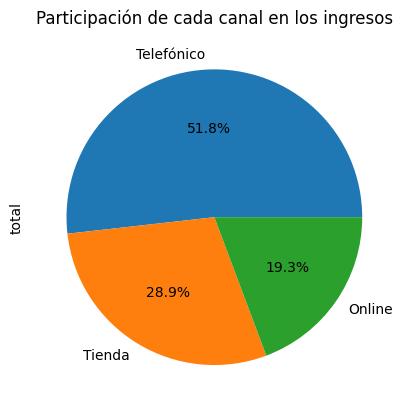

In [5]:
# Ejercicio 3


ing_canal = df.groupby('canal')['total'].sum().sort_values(ascending=False).head(5)
display (ing_canal)

ing_canal.plot.pie(autopct='%1.1f%%', title="Participación de cada canal en los ingresos")



### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

categoria,Arte,Corrección,Escritura,Organización,Papel
segmento,,,,,
Corporativo,2.807775,5.399568,30.237581,23.326134,38.228942
Mayorista,5.623472,12.224939,54.034230,5.623472,22.493888
Minorista,12.056738,12.765957,55.762411,4.255319,15.159574


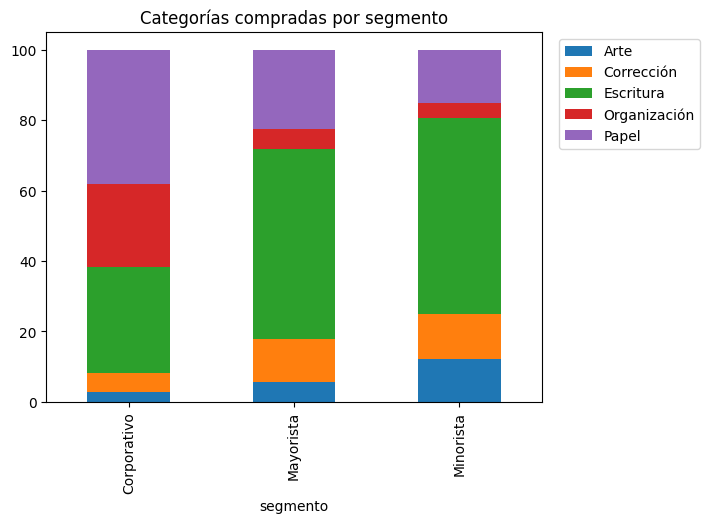

In [6]:
# Ejercicio 4

tabla_seg_cat = pd.crosstab(df['segmento'], df['categoria'], normalize="index") * 100
display(tabla_seg_cat)

tabla_seg_cat.plot.bar(stacked=True)
plt.title("Categorías compradas por segmento")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

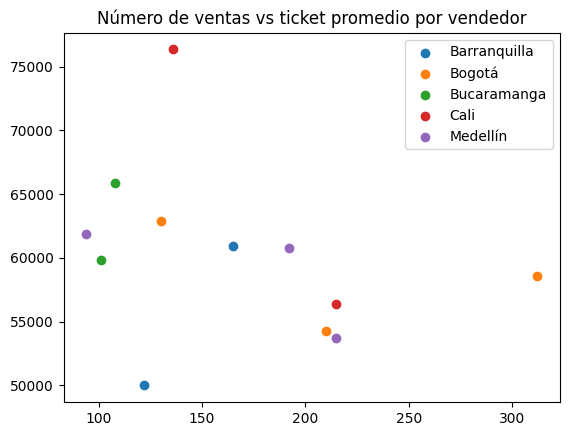

In [7]:
# Ejercicio 5

vend = df.groupby(['vendedor', 'ciudad']).agg(n_ventas=('total', 'count'), ticket_prom=('total', 'mean')).reset_index()

for ciudad, datos in vend.groupby('ciudad'):
    plt.scatter(datos['n_ventas'], datos['ticket_prom'], label=ciudad, )
plt.title("Número de ventas vs ticket promedio por vendedor")
plt.legend()
plt.show()

### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

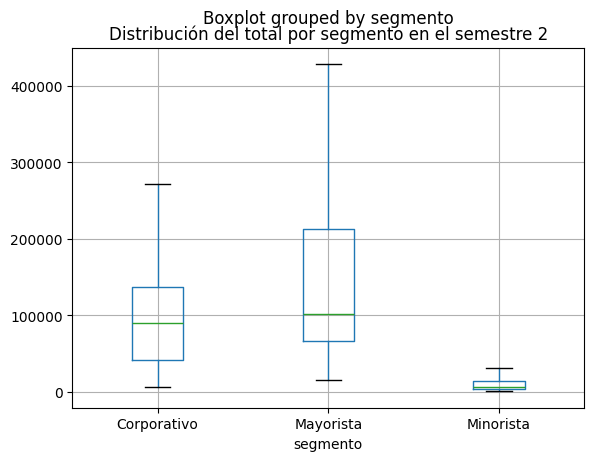

In [8]:
# Ejercicio 6

sem2 = df[df['mes'] >= 7]

sem2.boxplot(column='total', by='segmento', showfliers= False)

plt.title('Distribución del total por segmento en el semestre 2')
plt.show()


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [26]:
%%writefile figura_base.py
# Ejercicio 7: código de la figura 2x3


fig, axes = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(ax=axes[0, 0], title="Top 5 productos por ingresos")
ing_mes_ciudad.plot.line(ax=axes[0,1], title="Ventas Bogotá y Medellín", marker="o", xlabel="Mes", ylabel="Ingreso")
ing_canal.sort_values().plot.pie(ax=axes[0,2],title="Participación de cada canal en los ingresos", autopct='%1.1f%%', ylabel="Ingresos en porcentaje")



tabla_seg_cat.plot.bar(ax=axes[1,0], title="Categorías compradas por segmento", stacked=True)
for ciudad, datos in vend.groupby('ciudad'):
    axes[1, 1].scatter(datos['n_ventas'], datos['ticket_prom'], label=ciudad)
    axes[1, 1].set_title('Número de ventas vs ticket promedio por vendedor')
    axes[1, 1].set_xlabel('Número de ventas')
    axes[1, 1].set_ylabel('Ticket promedio')
    axes[1, 1].legend()
sem2.boxplot(ax=axes[1,2], column='total', by='segmento', showfliers= False )
axes[1, 2].set_title('Distribución del total por segmento en el semestre 2')

fig.suptitle("Gráficos ejercicio en cuadrícula")
plt.tight_layout()
plt.show()

Overwriting figura_base.py


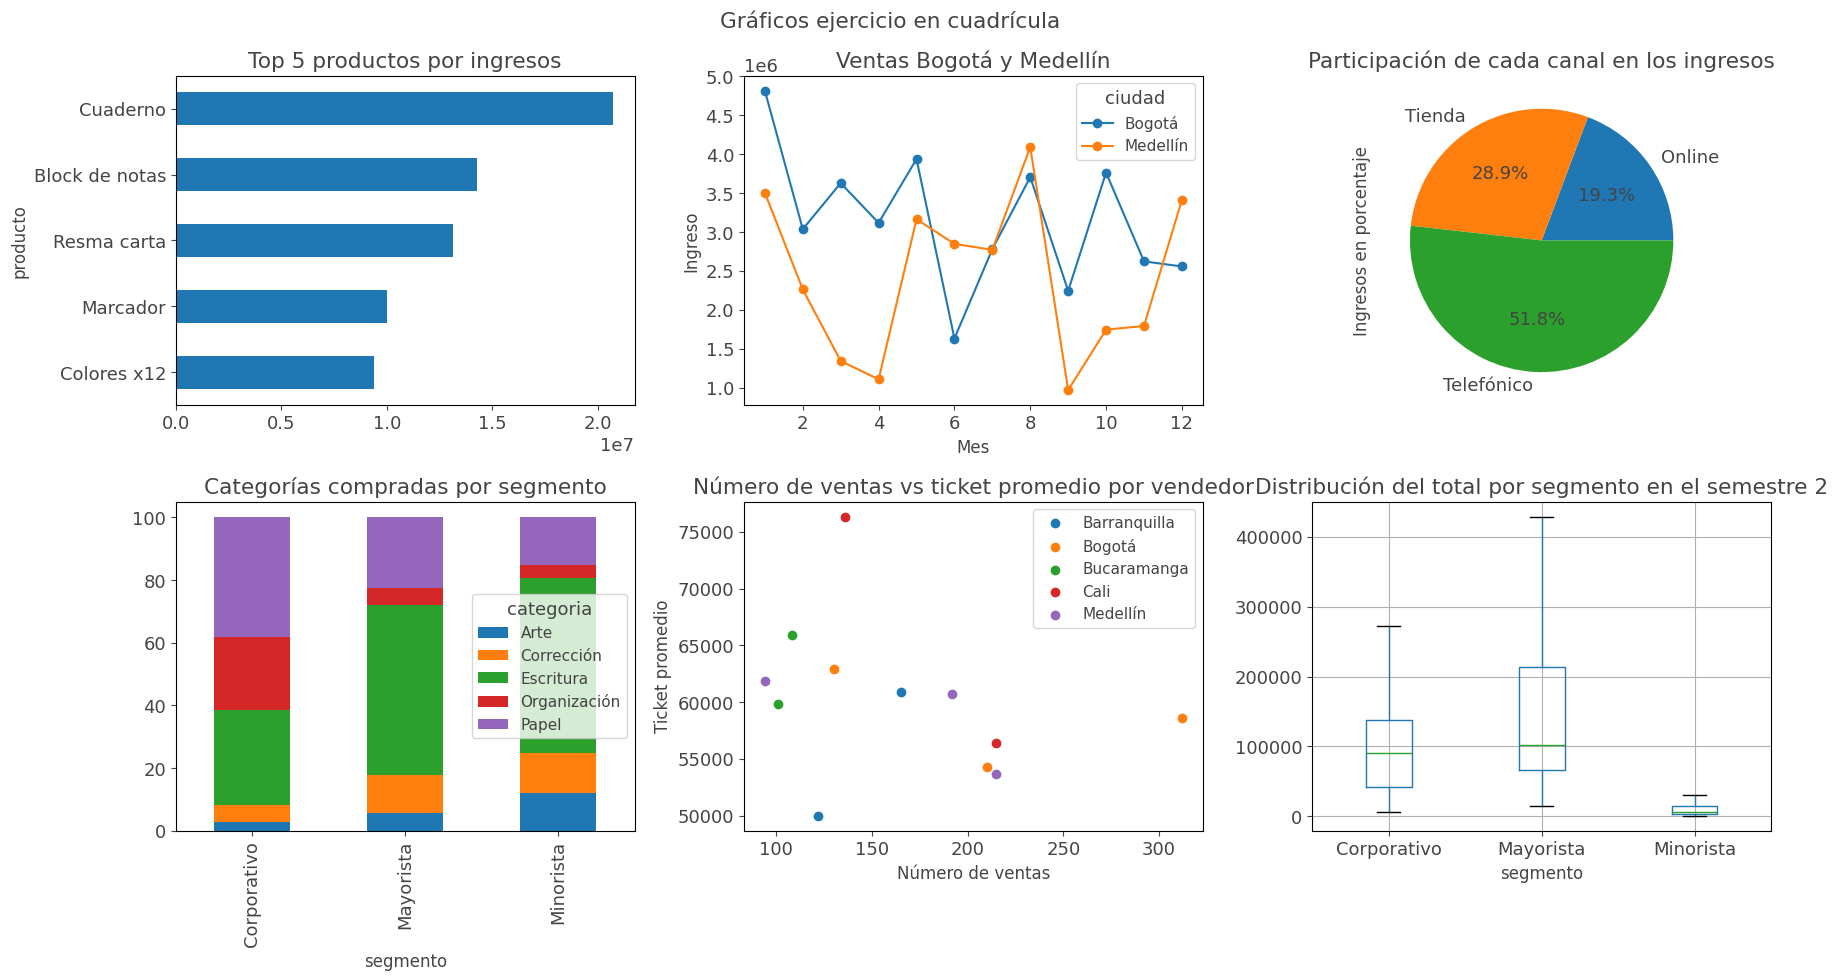

<Figure size 640x480 with 0 Axes>

In [27]:
%run -i figura_base.py

In [11]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [12]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
# Ejercicio 7: código de la figura 2x3


fig, axes = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(ax=axes[0, 0], title="Top 5 productos por ingresos")
ing_mes_ciudad.plot.line(ax=axes[0,1], title="Ventas Bogotá y Medellín", marker="o", xlabel="Mes", ylabel="Ingreso")
ing_canal.sort_values().plot.pie(ax=axes[0,2],title="Participación de cada canal en los ingresos", autopct='%1.1f%%', ylabel="Ingresos en porcentaje")



tabla_seg_cat.plot.bar(ax=axes[1,0], title="Categorías compradas por segmento", stacked=True)
for ciudad, datos in vend.groupby('ciudad'):
    axes[1, 1].scatter(datos['n_ventas'], datos['ticket_prom'], label=ciudad)
    axes[1, 1].set_title('Número de ventas vs ticket promedio por vendedor')
    axes[1, 1].set_xlabel('Número de ventas')
    axes[1, 1].set_ylabel('Ticket promedio')
    axes[1, 1].legend()
sem2.boxplot(ax=axes[1,2], column='total', by='segmento', showfliers= False )
axes[1, 2].s

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [13]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: La figura la verán la gerente general y los directores de la cadena en una junta, proyectada en una pantalla grande. Debe leerse desde lejos y, en 30 segundos, mostrar cómo le fue a la cadena en 2025 y dónde están las diferencias más importantes.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro (#F4F5F7) y paneles blancos. Usa un color fijo por ciudad en TODOS los gráficos donde aparezca una ciudad: Bogotá azul oscuro (#1F3A5F), Medellín naranja (#F28C28), Cali verde (#2E8B57), Barranquilla amarillo (#E8C020), Bucaramanga violeta (#7B4FA3). En los gráficos sin ciudades usa tonos de azul grisáceo y el azul oscuro solo para destacar lo más importante. Fuente sans-serif; títulos en negrita, alineados a la izquierda y en azul oscuro; título general de 22 pt.

TÍTULOS: Cada gráfico debe tener un título que diga la conclusión, calculada con los datos del código (no escrita a mano), por ejemplo "Cuaderno lidera: $ 21 M en ingresos", "Bogotá supera a Medellín" o "Telefónico: más de la mitad de los ingresos". Máximo dos líneas por título y sin que se corten.

EJES Y NÚMEROS: Muestra los pesos como "$ 20 M" (millones) o "$ 60 mil", sin notación científica. Cada eje con una etiqueta clara que incluya la unidad. En el gráfico de líneas, los meses con su inicial (E, F, M...). Porcentajes del pie con un decimal.

LIMPIEZA VISUAL: Quita los bordes superior y derecho de cada gráfico, usa cuadrícula suave solo en la dirección útil, escribe el valor sobre cada barra horizontal, deja las leyendas sin marco y pon bordes blancos entre las porciones del pie. Ningún texto debe quedar cortado ni superpuesto.
"""

print(prompt_v1)    # cópialo en la IA, junto con tu código y las reglas



PÚBLICO Y OBJETIVO: La figura la verán la gerente general y los directores de la cadena en una junta, proyectada en una pantalla grande. Debe leerse desde lejos y, en 30 segundos, mostrar cómo le fue a la cadena en 2025 y dónde están las diferencias más importantes.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro (#F4F5F7) y paneles blancos. Usa un color fijo por ciudad en TODOS los gráficos donde aparezca una ciudad: Bogotá azul oscuro (#1F3A5F), Medellín naranja (#F28C28), Cali verde (#2E8B57), Barranquilla amarillo (#E8C020), Bucaramanga violeta (#7B4FA3). En los gráficos sin ciudades usa tonos de azul grisáceo y el azul oscuro solo para destacar lo más importante. Fuente sans-serif; títulos en negrita, alineados a la izquierda y en azul oscuro; título general de 22 pt.

TÍTULOS: Cada gráfico debe tener un título que diga la conclusión, calculada con los datos del código (no escrita a mano), por ejemplo "Cuaderno lidera: $ 21 M en ingresos", "Bogotá supera a Medellín" o "Telefónico: más

In [14]:
%%writefile figura_v1.py
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Colores y estilo ----------
COLOR_CIUDAD = {"Bogotá": "#1F3A5F", "Medellín": "#F28C28", "Cali": "#2E8B57",
                "Barranquilla": "#E8C020", "Bucaramanga": "#7B4FA3"}
COLOR_CANAL = {"Telefónico": "#1F3A5F", "Tienda": "#8FA3BF", "Online": "#C9D3E0"}
AZUL, GRIS_TXT = "#1F3A5F", "#444444"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11})

def millones(x, pos=None):
    return f"\\$ {x/1e6:,.0f} M"       # \$ evita que matplotlib lo lea como fórmula

def mil(x, pos=None):
    return f"\\$ {x/1e3:,.0f} mil"

def limpiar(ax, grid="y"):
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    ax.grid(axis=grid, color="#E3E6EA", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

def titulo(ax, texto):
    ax.set_title(texto, loc="left", fontsize=13, fontweight="bold", color=AZUL, pad=12)

# ---------- Tablas (las mismas de la Parte A) ----------
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
comparacion = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = comparacion.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
ing_canal = df.groupby("canal")["total"].sum().sort_values(ascending=False)
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
vend = df.groupby(["vendedor", "ciudad"]).agg(n_ventas=("total", "count"), ticket_prom=("total", "mean")).reset_index()
sem2 = df[df["mes"] >= 7]

fig, axs = plt.subplots(2, 3, figsize=(18, 10), facecolor="#F4F5F7")
for ax in axs.flat:
    ax.set_facecolor("white")

# 1. Top 5 productos
ax = axs[0, 0]
t = top_productos.sort_values()
barras = ax.barh(t.index, t.values, color=[AZUL if p == t.index[-1] else "#8FA3BF" for p in t.index])
for b, v in zip(barras, t.values):
    ax.text(v + t.max() * 0.01, b.get_y() + b.get_height() / 2, millones(v), va="center", fontsize=10)
ax.xaxis.set_major_formatter(FuncFormatter(millones))
ax.set_xlim(0, t.max() * 1.2)
ax.set_xlabel("Ingresos del año")
limpiar(ax, "x")
titulo(ax, f"{t.index[-1]} lidera: {millones(t.max())} en ingresos")

# 2. Líneas Bogotá vs Medellín
ax = axs[0, 1]
for c in ing_mes_ciudad.columns:
    ax.plot(ing_mes_ciudad.index, ing_mes_ciudad[c], marker="o", linewidth=2.2, color=COLOR_CIUDAD[c], label=c)
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f"\\$ {x/1e6:.1f} M"))
ax.set_xlabel("Mes de 2025")
ax.set_ylabel("Ingresos mensuales")
limpiar(ax)
ax.legend(frameon=False)
tot = ing_mes_ciudad.sum()
titulo(ax, f"Bogotá supera a Medellín:\n{tot['Bogotá']/1e6:,.0f} M vs {tot['Medellín']/1e6:,.0f} M en el año")

# 3. Pie por canal
ax = axs[0, 2]
ax.pie(ing_canal.values, labels=ing_canal.index, autopct="%1.1f%%", startangle=90, counterclock=False,
       colors=[COLOR_CANAL[c] for c in ing_canal.index], radius=0.85, labeldistance=1.1,
       wedgeprops={"edgecolor": "white", "linewidth": 2})
titulo(ax, f"{ing_canal.index[0]}: más de la\nmitad de los ingresos")

# 4. Barras apiladas segmento x categoría
ax = axs[1, 0]
tabla_seg_cat.plot.bar(ax=ax, stacked=True, rot=0, width=0.6, legend=False,
                       color=["#C9D3E0", "#8FA3BF", "#1F3A5F", "#F28C28", "#2E8B57"])
ax.set_xlabel("Segmento de cliente")
ax.set_ylabel("% de las ventas del segmento")
ax.set_ylim(0, 100)
limpiar(ax)
ax.legend(title="Categoría", frameon=False, bbox_to_anchor=(1.0, 1.0), loc="upper left", fontsize=9)
titulo(ax, "Cada segmento compra distinto:\nlos corporativos piden más papel")

# 5. Dispersión de vendedores
ax = axs[1, 1]
for c, d in vend.groupby("ciudad"):
    ax.scatter(d["n_ventas"], d["ticket_prom"], s=90, color=COLOR_CIUDAD[c], label=c)
mejor = vend.loc[vend["n_ventas"].idxmax()]
ax.yaxis.set_major_formatter(FuncFormatter(mil))
ax.set_xlabel("Número de ventas en el año")
ax.set_ylabel("Ticket promedio")
limpiar(ax, "both")
ax.legend(frameon=False, fontsize=9)
titulo(ax, f"{mejor['vendedor']} lidera en ventas ({int(mejor['n_ventas'])})")

# 6. Cajas por segmento (segundo semestre)
ax = axs[1, 2]
sem2.boxplot(column="total", by="segmento", showfliers=False, ax=ax)
ax.yaxis.set_major_formatter(FuncFormatter(mil))
ax.set_xlabel("Segmento de cliente")
ax.set_ylabel("Valor de la venta")
limpiar(ax)
ax.set_title("")   # boxplot(by=...) pone su propio título
titulo(ax, "Las ventas mayoristas son\nlas más grandes (2.º semestre)")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=22, fontweight="bold", color=AZUL, x=0.01, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.95])


Writing figura_v1.py


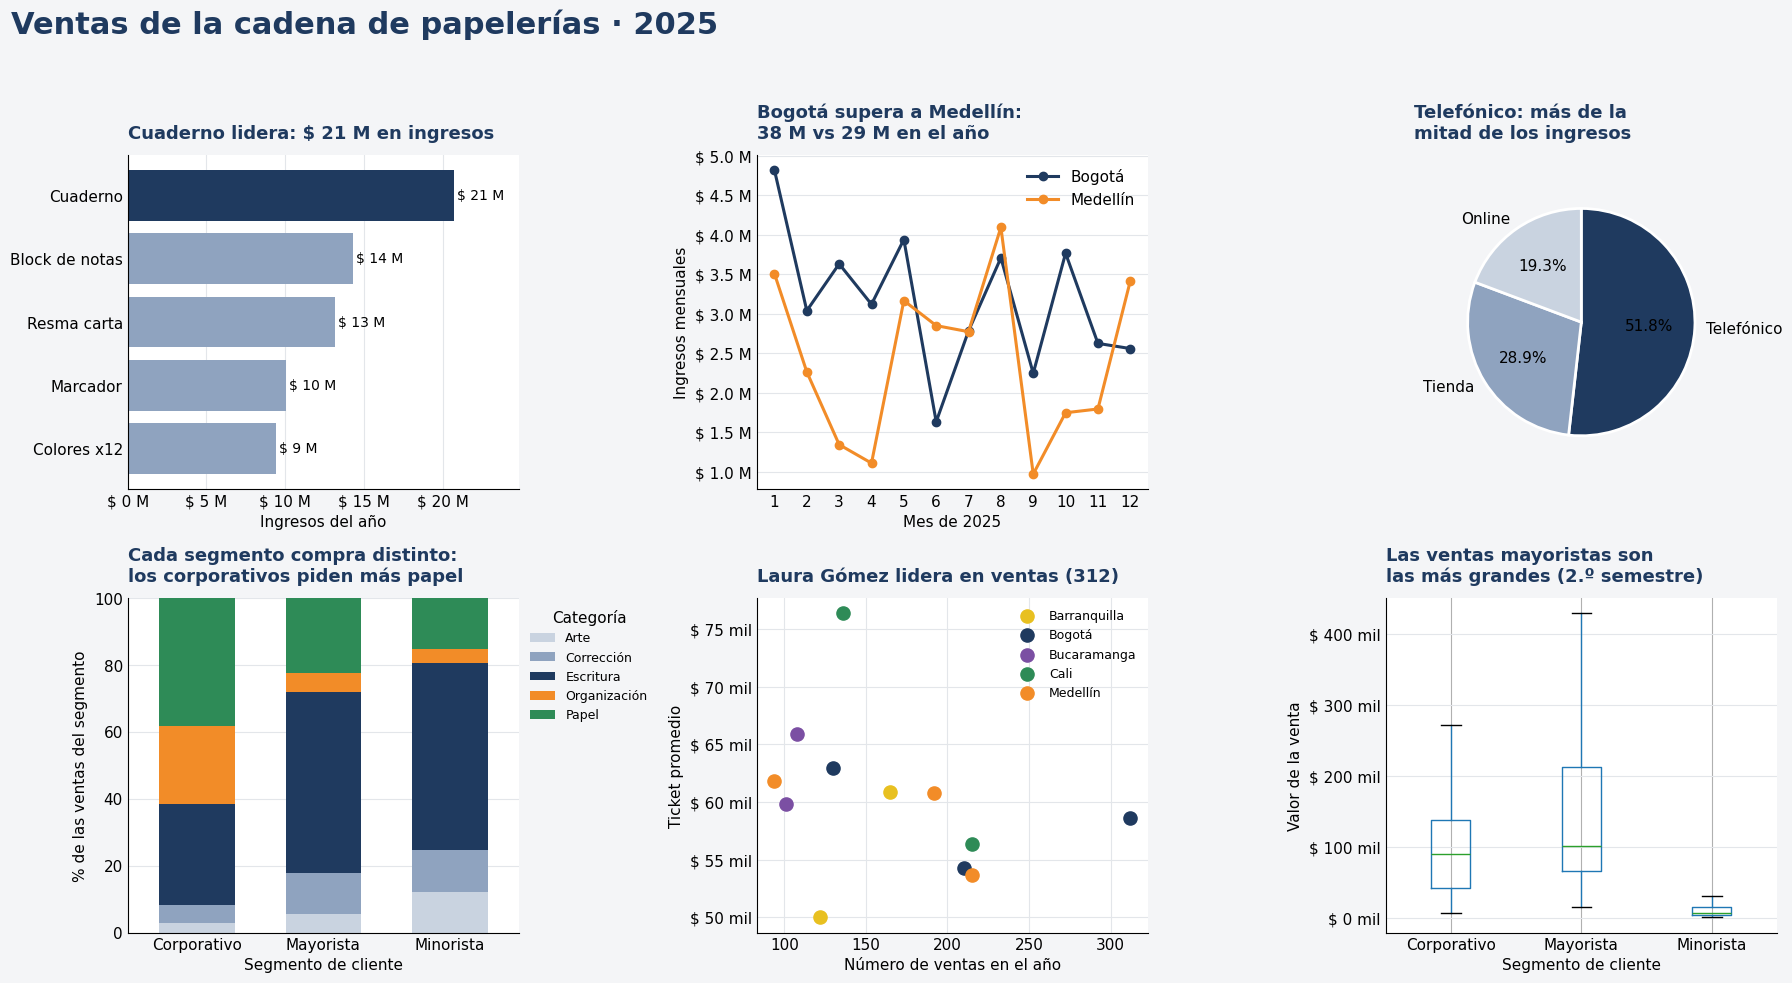

In [15]:
mostrar("v1")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [16]:
prompt_v2 = prompt_v1 + """

AJUSTES (sobre lo que vi en la versión 1: la letra se ve pequeña para proyectarla, el pie no deja ver bien la participación y el gráfico de líneas no destaca nada):
1. Cambia el pie por una dona.
2. En el gráfico de líneas, anota el mes de mayor ingreso de cada ciudad con su valor, en el color de esa ciudad.
3. Agranda la letra: base de 13 pt, títulos de 14 pt, y los puntos de la dispersión más grandes.
Conserva todo lo demás de la versión 1 (colores por ciudad, títulos con conclusión, formatos de pesos).
"""

print(prompt_v2)    # cópialo en la IA, junto con tu código base y las reglas



PÚBLICO Y OBJETIVO: La figura la verán la gerente general y los directores de la cadena en una junta, proyectada en una pantalla grande. Debe leerse desde lejos y, en 30 segundos, mostrar cómo le fue a la cadena en 2025 y dónde están las diferencias más importantes.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro (#F4F5F7) y paneles blancos. Usa un color fijo por ciudad en TODOS los gráficos donde aparezca una ciudad: Bogotá azul oscuro (#1F3A5F), Medellín naranja (#F28C28), Cali verde (#2E8B57), Barranquilla amarillo (#E8C020), Bucaramanga violeta (#7B4FA3). En los gráficos sin ciudades usa tonos de azul grisáceo y el azul oscuro solo para destacar lo más importante. Fuente sans-serif; títulos en negrita, alineados a la izquierda y en azul oscuro; título general de 22 pt.

TÍTULOS: Cada gráfico debe tener un título que diga la conclusión, calculada con los datos del código (no escrita a mano), por ejemplo "Cuaderno lidera: $ 21 M en ingresos", "Bogotá supera a Medellín" o "Telefónico: más

In [17]:
%%writefile figura_v2.py
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Colores y estilo ----------
COLOR_CIUDAD = {"Bogotá": "#1F3A5F", "Medellín": "#F28C28", "Cali": "#2E8B57",
                "Barranquilla": "#E8C020", "Bucaramanga": "#7B4FA3"}
COLOR_CANAL = {"Telefónico": "#1F3A5F", "Tienda": "#8FA3BF", "Online": "#C9D3E0"}
AZUL, GRIS_TXT = "#1F3A5F", "#444444"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 13})

def millones(x, pos=None):
    return f"\\$ {x/1e6:,.0f} M"       # \$ evita que matplotlib lo lea como fórmula

def mil(x, pos=None):
    return f"\\$ {x/1e3:,.0f} mil"

def limpiar(ax, grid="y"):
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    ax.grid(axis=grid, color="#E3E6EA", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

def titulo(ax, texto):
    ax.set_title(texto, loc="left", fontsize=14, fontweight="bold", color=AZUL, pad=14)

# ---------- Tablas (las mismas de la Parte A) ----------
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
comparacion = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = comparacion.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
ing_canal = df.groupby("canal")["total"].sum().sort_values(ascending=False)
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
vend = df.groupby(["vendedor", "ciudad"]).agg(n_ventas=("total", "count"), ticket_prom=("total", "mean")).reset_index()
sem2 = df[df["mes"] >= 7]

fig, axs = plt.subplots(2, 3, figsize=(18, 10), facecolor="#F4F5F7")
for ax in axs.flat:
    ax.set_facecolor("white")

# 1. Top 5 productos
ax = axs[0, 0]
t = top_productos.sort_values()
barras = ax.barh(t.index, t.values, color=[AZUL if p == t.index[-1] else "#8FA3BF" for p in t.index])
for b, v in zip(barras, t.values):
    ax.text(v + t.max() * 0.01, b.get_y() + b.get_height() / 2, millones(v), va="center", fontsize=10)
ax.xaxis.set_major_formatter(FuncFormatter(millones))
ax.set_xlim(0, t.max() * 1.2)
ax.set_xlabel("Ingresos del año")
limpiar(ax, "x")
titulo(ax, f"{t.index[-1]} lidera: {millones(t.max())} en ingresos")

# 2. Líneas Bogotá vs Medellín
ax = axs[0, 1]
for c in ing_mes_ciudad.columns:
    ax.plot(ing_mes_ciudad.index, ing_mes_ciudad[c], marker="o", linewidth=2.2, color=COLOR_CIUDAD[c], label=c)
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f"\\$ {x/1e6:.1f} M"))
ax.set_xlabel("Mes de 2025")
ax.set_ylabel("Ingresos mensuales")
for c in ing_mes_ciudad.columns:
    m = ing_mes_ciudad[c].idxmax()
    val = ing_mes_ciudad[c].max()
    ax.annotate(f"Máx. {c}: {millones(val)}", (m, val), textcoords="offset points", xytext=(12, 8),
                fontsize=10, color=COLOR_CIUDAD[c], fontweight="bold")
ax.set_ylim(0, ing_mes_ciudad.max().max() * 1.2)
limpiar(ax)
ax.legend(frameon=False, loc="lower center", ncol=2)
tot = ing_mes_ciudad.sum()
titulo(ax, f"Bogotá supera a Medellín:\n{tot['Bogotá']/1e6:,.0f} M vs {tot['Medellín']/1e6:,.0f} M en el año")

# 3. Pie por canal
ax = axs[0, 2]
ax.pie(ing_canal.values, labels=ing_canal.index, autopct="%1.1f%%", startangle=90, counterclock=False,
       colors=[COLOR_CANAL[c] for c in ing_canal.index], radius=0.85, labeldistance=1.1,
       wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.45})
titulo(ax, f"{ing_canal.index[0]}: más de la\nmitad de los ingresos")

# 4. Barras apiladas segmento x categoría
ax = axs[1, 0]
tabla_seg_cat.plot.bar(ax=ax, stacked=True, rot=0, width=0.6, legend=False,
                       color=["#C9D3E0", "#8FA3BF", "#1F3A5F", "#F28C28", "#2E8B57"])
ax.set_xlabel("Segmento de cliente")
ax.set_ylabel("% de las ventas del segmento")
ax.set_ylim(0, 100)
limpiar(ax)
ax.legend(title="Categoría", frameon=False, bbox_to_anchor=(1.0, 1.0), loc="upper left", fontsize=9)
titulo(ax, "Cada segmento compra distinto:\nlos corporativos piden más papel")

# 5. Dispersión de vendedores
ax = axs[1, 1]
for c, d in vend.groupby("ciudad"):
    ax.scatter(d["n_ventas"], d["ticket_prom"], s=170, color=COLOR_CIUDAD[c], label=c)
mejor = vend.loc[vend["n_ventas"].idxmax()]
ax.yaxis.set_major_formatter(FuncFormatter(mil))
ax.set_xlabel("Número de ventas en el año")
ax.set_ylabel("Ticket promedio")
limpiar(ax, "both")
ax.legend(frameon=False, fontsize=9)
titulo(ax, f"{mejor['vendedor']} lidera en ventas ({int(mejor['n_ventas'])})")

# 6. Cajas por segmento (segundo semestre)
ax = axs[1, 2]
sem2.boxplot(column="total", by="segmento", showfliers=False, ax=ax)
ax.yaxis.set_major_formatter(FuncFormatter(mil))
ax.set_xlabel("Segmento de cliente")
ax.set_ylabel("Valor de la venta")
limpiar(ax)
ax.set_title("")   # boxplot(by=...) pone su propio título
titulo(ax, "Las ventas mayoristas son\nlas más grandes (2.º semestre)")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=26, fontweight="bold", color=AZUL, x=0.01, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.95])


Writing figura_v2.py


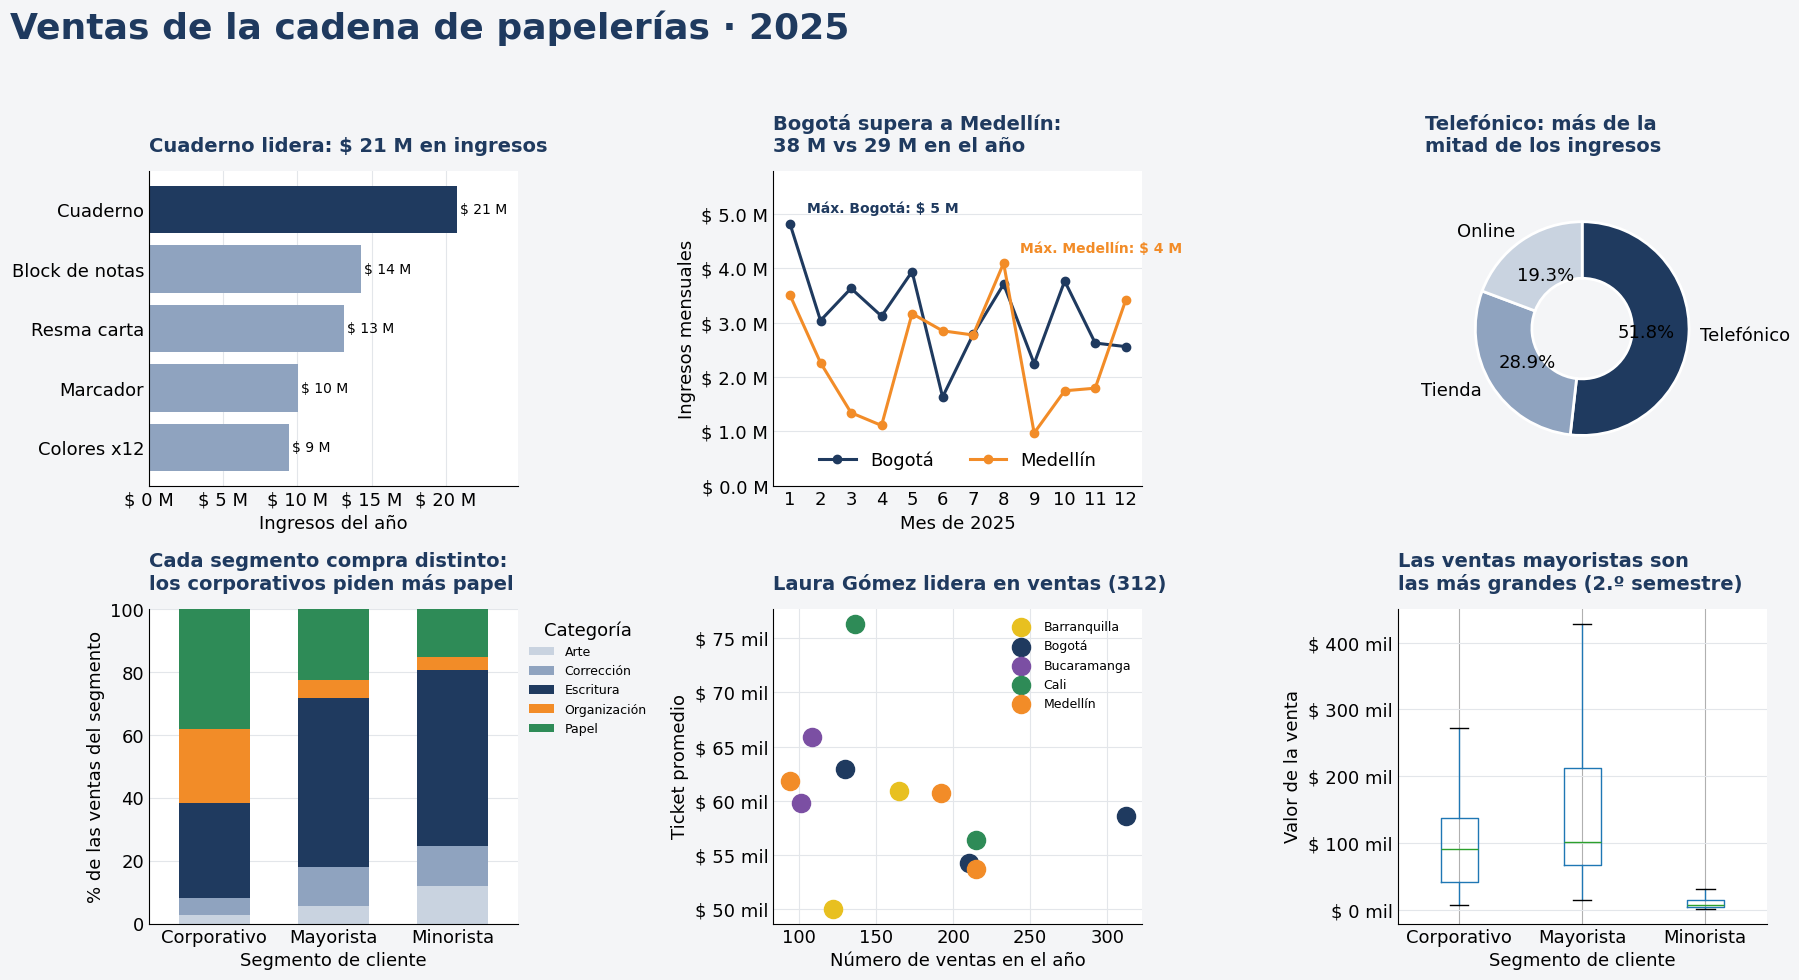

In [18]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [19]:
prompt_v3 = prompt_v2 + """

AJUSTES FINALES (sobre lo que vi en la versión 2: la escala del boxplot no deja ver a Minorista, el título de las barras apiladas no coincide con los datos y los colores de las barras se distinguen poco):

1. La escala del boxplot no permite ver bien la parte de minorista. Necesito que mejores la visualización de esta grafica adhiriéndote a los objetivos de visualización estipulados antes.

2. Corrige el título del gráfico de barras apiladas: debe calcularse con la categoría de mayor porcentaje en cada segmento, no escribirse a mano. Según los datos, Papel solo predomina en Corporativo (38,2 %); en Mayorista y Minorista predomina Escritura (54 % y 56 %).

3. Los colores son difíciles de distinguir: en las barras apiladas usa cinco colores claramente distintos entre sí para las categorías, sin repetir los colores de las ciudades. En las barras horizontales, mantén el Cuaderno en azul oscuro (#1F3A5F), pero pinta los otros cuatro productos en una escala de azules que vaya de medio a claro, para que se note el orden de mayor a menor.

Conserva todo lo demás de la versión 2.

4. Los colores de la gráfica de barras apiladas están muy vivos y el rosado quita seriedad: usa tonos sobrios y apagados para las cinco categorías, que se sigan distinguiendo entre sí.

5. Mantén la misma figura, pero con un acabado un poco más profesional: textos y ejes en gris oscuro, bordes de los ejes en gris claro, cuadrícula más suave y puntos de la dispersión con borde blanco.
"""

print(prompt_v3)    # cópialo en la IA, junto con tu código base y las reglas


PÚBLICO Y OBJETIVO: La figura la verán la gerente general y los directores de la cadena en una junta, proyectada en una pantalla grande. Debe leerse desde lejos y, en 30 segundos, mostrar cómo le fue a la cadena en 2025 y dónde están las diferencias más importantes.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro (#F4F5F7) y paneles blancos. Usa un color fijo por ciudad en TODOS los gráficos donde aparezca una ciudad: Bogotá azul oscuro (#1F3A5F), Medellín naranja (#F28C28), Cali verde (#2E8B57), Barranquilla amarillo (#E8C020), Bucaramanga violeta (#7B4FA3). En los gráficos sin ciudades usa tonos de azul grisáceo y el azul oscuro solo para destacar lo más importante. Fuente sans-serif; títulos en negrita, alineados a la izquierda y en azul oscuro; título general de 22 pt.

TÍTULOS: Cada gráfico debe tener un título que diga la conclusión, calculada con los datos del código (no escrita a mano), por ejemplo "Cuaderno lidera: $ 21 M en ingresos", "Bogotá supera a Medellín" o "Telefónico: más

In [20]:
%%writefile figura_v3.py
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, FixedLocator

# ---------- Colores y estilo ----------
COLOR_CIUDAD = {"Bogotá": "#1F3A5F", "Medellín": "#F28C28", "Cali": "#2E8B57",
                "Barranquilla": "#E8C020", "Bucaramanga": "#7B4FA3"}
COLOR_CANAL = {"Telefónico": "#1F3A5F", "Tienda": "#8FA3BF", "Online": "#C9D3E0"}
AZUL, GRIS_TXT = "#1F3A5F", "#444444"
# Cinco colores bien distintos para las categorías, sin repetir los de las ciudades
# Tonos sobrios y bien distintos para las categorías, sin repetir los de las ciudades
COLOR_CATEGORIA = {"Arte": "#A05C5C", "Corrección": "#C2A878", "Escritura": "#4F7CAC",
                   "Organización": "#7A9E9F", "Papel": "#3D4B5C"}
# Escala de azules de medio a claro para los productos 2 a 5
AZULES_ESCALA = ["#4A6FA5", "#7393C2", "#9FB6D9", "#C9D7EC"]
plt.rcParams.update({"font.family": "sans-serif", "font.size": 13,
                     "text.color": GRIS_TXT, "axes.labelcolor": GRIS_TXT,
                     "xtick.color": GRIS_TXT, "ytick.color": GRIS_TXT,
                     "axes.labelsize": 12, "legend.fontsize": 11})

def millones(x, pos=None):
    return f"\\$ {x/1e6:,.0f} M"       # \$ evita que matplotlib lo lea como fórmula

def mil(x, pos=None):
    return f"\\$ {x/1e3:,.0f} mil"

def limpiar(ax, grid="y"):
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    for lado in ["left", "bottom"]:
        ax.spines[lado].set_color("#B8BEC6")
    ax.grid(axis=grid, color="#E8EBEF", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

def titulo(ax, texto):
    ax.set_title(texto, loc="left", fontsize=14, fontweight="bold", color=AZUL, pad=14)

# ---------- Tablas (las mismas de la Parte A) ----------
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
comparacion = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = comparacion.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
ing_canal = df.groupby("canal")["total"].sum().sort_values(ascending=False)
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
vend = df.groupby(["vendedor", "ciudad"]).agg(n_ventas=("total", "count"), ticket_prom=("total", "mean")).reset_index()
sem2 = df[df["mes"] >= 7]

fig, axs = plt.subplots(2, 3, figsize=(18, 10), facecolor="#F4F5F7")
for ax in axs.flat:
    ax.set_facecolor("white")

# 1. Top 5 productos
ax = axs[0, 0]
t = top_productos.sort_values()
colores_top = AZULES_ESCALA[::-1][:len(t) - 1] + [AZUL]   # t va de menor a mayor
barras = ax.barh(t.index, t.values, color=colores_top)
for b, v in zip(barras, t.values):
    ax.text(v + t.max() * 0.01, b.get_y() + b.get_height() / 2, millones(v), va="center", fontsize=10)
ax.xaxis.set_major_formatter(FuncFormatter(millones))
ax.set_xlim(0, t.max() * 1.2)
ax.set_xlabel("Ingresos del año")
limpiar(ax, "x")
titulo(ax, f"{t.index[-1]} lidera: {millones(t.max())} en ingresos")

# 2. Líneas Bogotá vs Medellín
ax = axs[0, 1]
for c in ing_mes_ciudad.columns:
    ax.plot(ing_mes_ciudad.index, ing_mes_ciudad[c], marker="o", markersize=5, linewidth=2, color=COLOR_CIUDAD[c], label=c)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f"\\$ {x/1e6:.1f} M"))
ax.set_xlabel("Mes de 2025")
ax.set_ylabel("Ingresos mensuales")
for c in ing_mes_ciudad.columns:
    m = ing_mes_ciudad[c].idxmax()
    val = ing_mes_ciudad[c].max()
    ax.annotate(f"Máx. {c}: \\$ {val/1e6:.1f} M", (m, val), textcoords="offset points", xytext=(12, 8),
                fontsize=10, color=COLOR_CIUDAD[c], fontweight="bold")
ax.set_ylim(0, ing_mes_ciudad.max().max() * 1.2)
limpiar(ax)
ax.legend(frameon=False, loc="lower center", ncol=2)
tot = ing_mes_ciudad.sum()
titulo(ax, f"Bogotá supera a Medellín:\n{millones(tot['Bogotá'])} vs {millones(tot['Medellín'])} en el año")

# 3. Pie por canal
ax = axs[0, 2]
_, _, porcentajes = ax.pie(ing_canal.values, labels=ing_canal.index, autopct="%1.1f%%", startangle=90, counterclock=False,
       colors=[COLOR_CANAL[c] for c in ing_canal.index], radius=0.85, labeldistance=1.1, pctdistance=0.71,
       wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.5})
for p in porcentajes:
    p.set_fontsize(11)
porcentajes[0].set_color("white")   # se lee sobre el azul oscuro
porcentajes[0].set_fontweight("bold")
titulo(ax, f"{ing_canal.index[0]}: más de la\nmitad de los ingresos")

# 4. Barras apiladas segmento x categoría
ax = axs[1, 0]
tabla_seg_cat.plot.bar(ax=ax, stacked=True, rot=0, width=0.6, legend=False,
                       color=[COLOR_CATEGORIA[c] for c in tabla_seg_cat.columns],
                       edgecolor="white", linewidth=1)
ax.set_xlabel("Segmento de cliente")
ax.set_ylabel("% de las ventas del segmento")
ax.set_ylim(0, 100)
limpiar(ax)
ax.legend(title="Categoría", frameon=False, bbox_to_anchor=(1.0, 1.0), loc="upper left", fontsize=11)
lider = tabla_seg_cat.idxmax(axis=1)          # categoría con mayor % en cada segmento
grupos = lider.groupby(lider).apply(lambda s: " y ".join(s.index))
partes = [f"{cat} domina en {segs}" for cat, segs in grupos.sort_values(key=lambda x: x.str.len(), ascending=False).items()]
titulo(ax, ";\n".join(partes))

# 5. Dispersión de vendedores
ax = axs[1, 1]
for c, d in vend.groupby("ciudad"):
    ax.scatter(d["n_ventas"], d["ticket_prom"], s=150, color=COLOR_CIUDAD[c], label=c,
               alpha=0.9, edgecolor="white", linewidth=1)
mejor = vend.loc[vend["n_ventas"].idxmax()]
ax.yaxis.set_major_formatter(FuncFormatter(mil))
ax.set_xlabel("Número de ventas en el año")
ax.set_ylabel("Ticket promedio")
limpiar(ax, "both")
ax.legend(frameon=False, fontsize=11)
titulo(ax, f"{mejor['vendedor']} lidera en ventas ({int(mejor['n_ventas'])})")

# 6. Cajas por segmento (segundo semestre)
ax = axs[1, 2]
sem2.boxplot(column="total", by="segmento", showfliers=False, ax=ax, patch_artist=True,
             boxprops={"facecolor": "#C9D7EC", "edgecolor": AZUL},
             medianprops={"color": AZUL, "linewidth": 2.5},
             whiskerprops={"color": AZUL}, capprops={"color": AZUL})
ax.set_yscale("log")   # escala logarítmica: así se ve Minorista junto a los demás
ax.yaxis.set_major_locator(FixedLocator([2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 200_000, 500_000]))
ax.yaxis.set_minor_locator(FixedLocator([]))
ax.yaxis.set_major_formatter(FuncFormatter(mil))
medianas = sem2.groupby("segmento")["total"].median()
for i, (seg, med) in enumerate(medianas.items(), start=1):
    ax.annotate(mil(med), (i, med), textcoords="offset points", xytext=(26, -4),
                fontsize=10, color=AZUL, fontweight="bold")
ax.set_xlabel("Segmento de cliente")
ax.set_ylabel("Valor de la venta (escala logarítmica)")
limpiar(ax)
ax.set_title("")   # boxplot(by=...) pone su propio título
ax.set_xlim(0.5, len(medianas) + 0.9)   # espacio para la etiqueta de la última caja
titulo(ax, f"2.º semestre: {medianas.idxmax()} hace\nlas ventas más grandes ({mil(medianas.max())})")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=26, fontweight="bold", color=AZUL, x=0.01, ha="left")
plt.tight_layout(rect=[0, 0, 0.98, 0.95])

Writing figura_v3.py


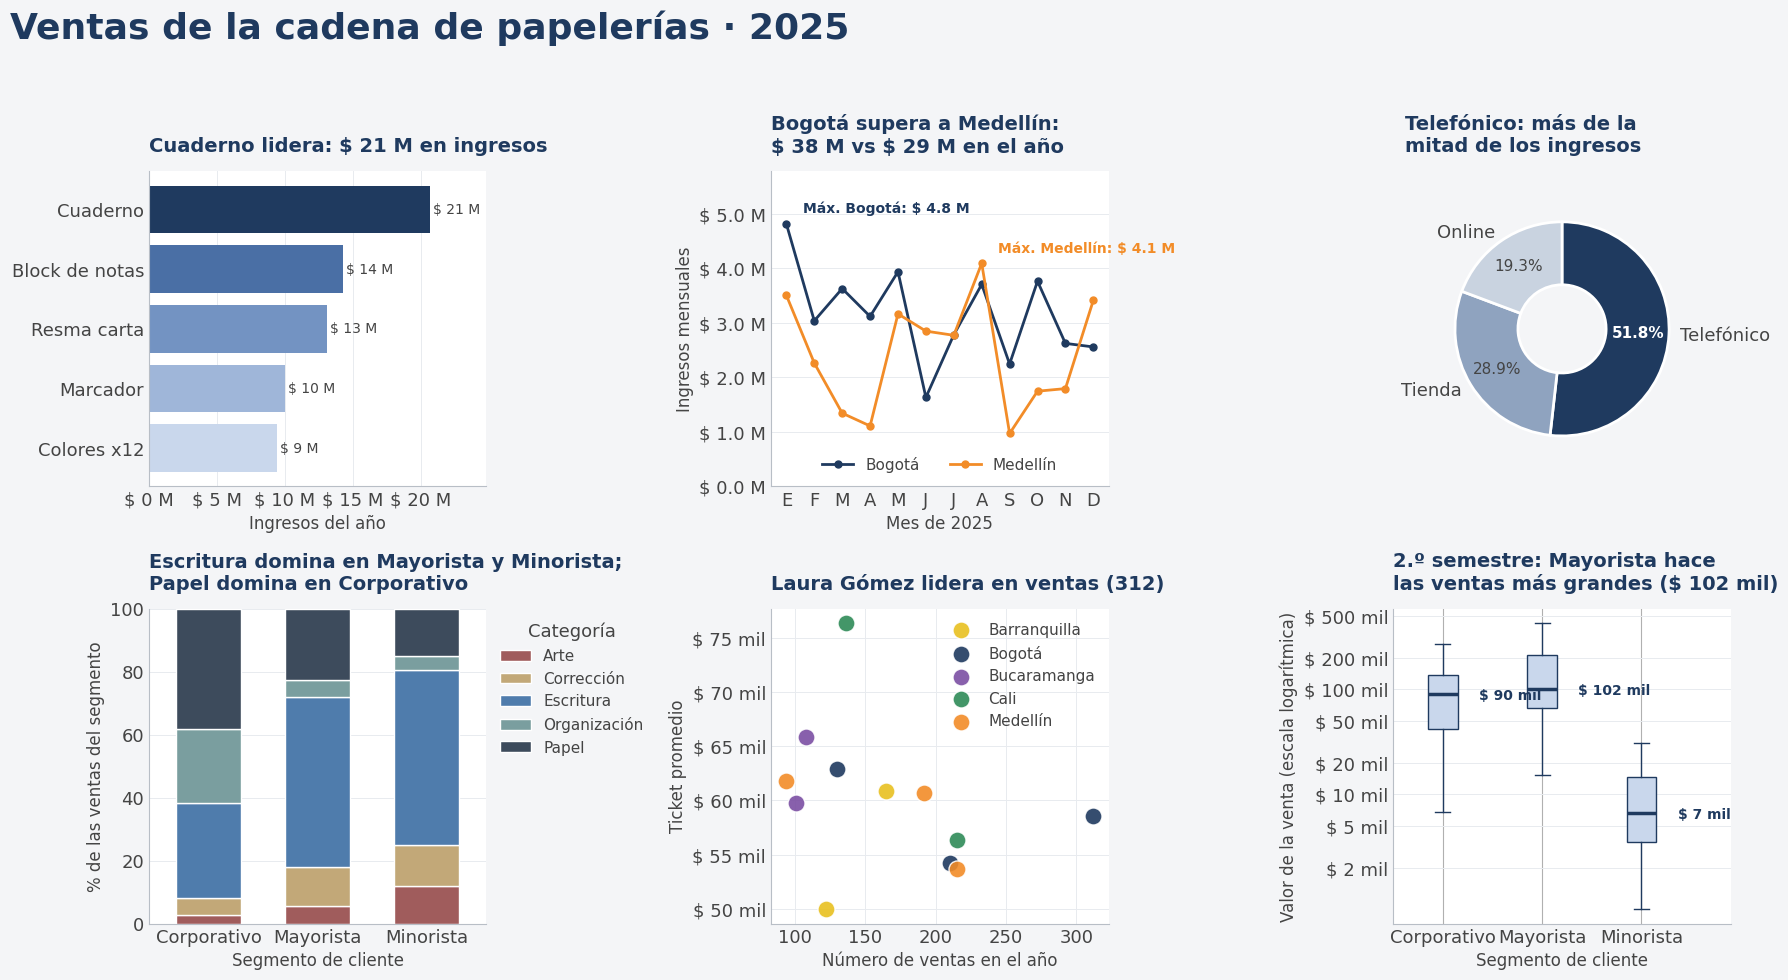

In [21]:
mostrar("v3")

In [22]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

Parte C correcta ✔


---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [23]:
figura_elegida = "v3"      # cambia por "v1", "v2" o "v3"

hallazgos = [
    "Bogotá genera el 31,9 % de los ingresos de la cadena ($ 37,8 M de $ 118,7 M), seguida de Medellín con el 24,5 %.",
    "El canal Telefónico aporta el 51,8 % de los ingresos con solo 545 de las 2.000 ventas, porque su venta promedio ($ 112.754) más que triplica la del canal Online ($ 33.958).",
    "Los clientes corporativos compran distinto: el 38,2 % de sus ventas es Papel y el 23,3 % Organización, frente a 15,2 % y 4,3 % en los minoristas.",
]


In [24]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

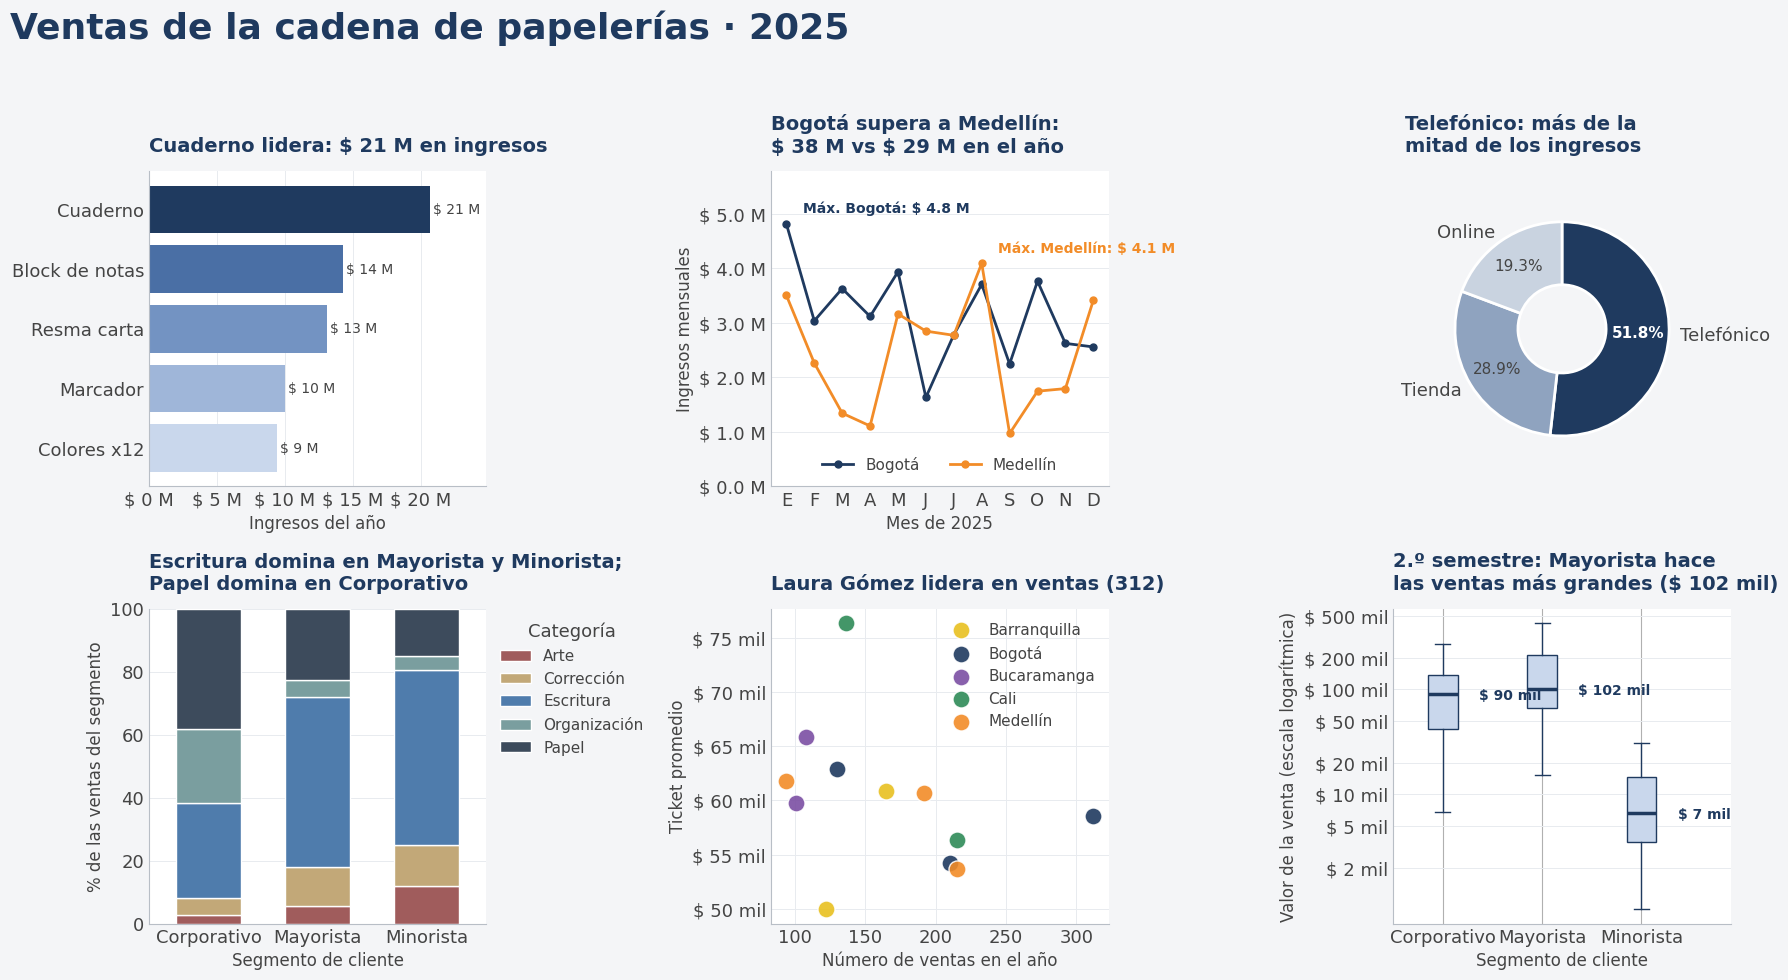

Hallazgos:
• Bogotá genera el 31,9 % de los ingresos de la cadena ($ 37,8 M de $ 118,7 M), seguida de Medellín con el 24,5 %.
• El canal Telefónico aporta el 51,8 % de los ingresos con solo 545 de las 2.000 ventas, porque su venta promedio ($ 112.754) más que triplica la del canal Online ($ 33.958).
• Los clientes corporativos compran distinto: el 38,2 % de sus ventas es Papel y el 23,3 % Organización, frente a 15,2 % y 4,3 % en los minoristas.


In [25]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook).

## Prompts y correcciones

**Prompts usados:** `prompt_v1`, `prompt_v2` y `prompt_v3` (en las celdas de los Ejercicios 8, 9 y 10 de arriba).

**Qué tuve que corregir de lo que hizo la IA y cómo lo pedí:**
1. Los títulos con "$" salían en cursiva y con símbolos raros, porque matplotlib interpreta dos "$" como una fórmula; pedí escribir el signo como `\$` en todos los textos.
2. El diagrama de cajas traía su propio título ("total") encima del título que pedí y algunos títulos largos se cortaban; pedí borrar ese título automático y partir los títulos en dos líneas.
3. El eje de millones del gráfico de líneas repetía valores ("$ 4 M", "$ 4 M"); pedí mostrar un decimal, conservando las cifras de mis tablas.
4. La IA escribió un título falso en las barras apiladas (decía que el Papel predomina en todos los segmentos, cuando en Mayorista y Minorista predomina Escritura), el boxplot no dejaba ver a Minorista y los colores eran poco distinguibles o muy vivos; en `prompt_v3` pedí calcular el título con los datos, una escala que permitiera ver Minorista y colores sobrios y distintos entre sí.
